In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your file
df = pd.read_csv(r"D:\College\Research\\Astrophysics\ProjectTry\yolo-dagn\gothic_catalog.csv")

# Quick check
print(df.head())
print(df.columns)

                 ObjID           SpecObjID         RA       DEC  Redshift  \
0  1237650795683512507  299496274514700288  146.95607 -0.342300  0.134680   
1  1237651799621959813  299504520851908608  146.57273 -1.060836  0.060614   
2  1237650795146182725  299516890357721088  146.00779 -0.642272  0.004776   
3  1237650796220121207  299533383032137728  146.34706  0.075416  0.062282   
4  1237650795682791609  299561970334459904  145.36478 -0.342794  0.148621   

   dist_arcsec   dist_kpc  delta_s_kpc  gothic_dist_arcsec  gothic_delta_s_kpc  
0     9.077988  21.678026    25.045581            5.791130           16.530084  
1     9.824729  11.497394    12.199280            6.664669            8.051525  
2     8.773010   0.864970     0.858377            5.434367            0.566529  
3     9.420687  11.305631    12.019348            6.192019            7.932770  
4    10.522603  27.299434    32.036252            7.481041           21.143927  
Index(['ObjID', 'SpecObjID', 'RA', 'DEC', 'Redshift

In [2]:
# Number of bins
bin_width = 1
bins = np.arange(0, df['gothic_dist_arcsec'].max() + bin_width, bin_width)
# bins_arcsec = 20

# Calculate histogram
freq_arcsec, edges_arcsec = np.histogram(
    df['gothic_dist_arcsec'].dropna(),
    bins=bins
)

cumfreq_arcsec = np.cumsum(freq_arcsec)

# Statistics table
arcsec_table = pd.DataFrame({
    'Bin Left Edge': edges_arcsec[:-1],
    'Bin Right Edge': edges_arcsec[1:],
    'Frequency': freq_arcsec,
    'Cumulative Frequency': cumfreq_arcsec
})

arcsec_table

,Bin Left Edge,Bin Right Edge,Frequency,Cumulative Frequency
0,0.0,1.0,133,133
1,1.0,2.0,926,1059
2,2.0,3.0,2584,3643
3,3.0,4.0,4543,8186
4,4.0,5.0,5587,13773
5,5.0,6.0,5531,19304
6,6.0,7.0,4424,23728
7,7.0,8.0,2758,26486
8,8.0,9.0,1512,27998
9,9.0,10.0,735,28733


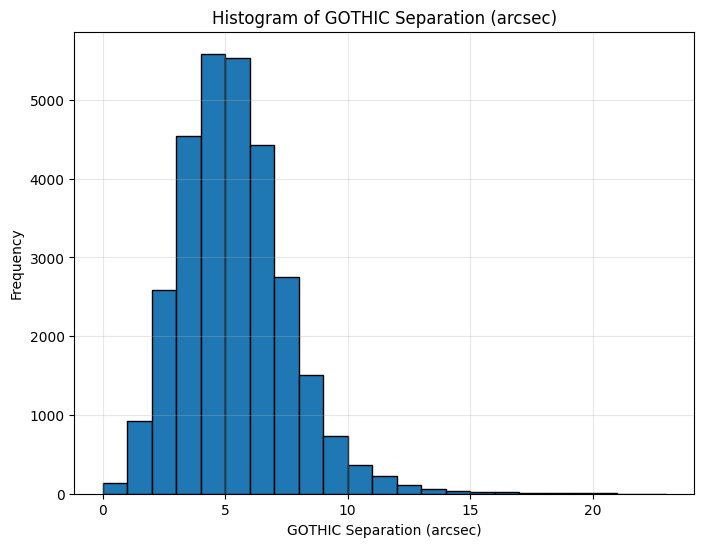

In [3]:
plt.figure(figsize=(8,6))

plt.hist(
    df['gothic_dist_arcsec'].dropna(),
    bins=bins,
    edgecolor='black'
)

plt.xlabel('GOTHIC Separation (arcsec)')
plt.ylabel('Frequency')
plt.title('Histogram of GOTHIC Separation (arcsec)')
plt.grid(alpha=0.3)

plt.show()

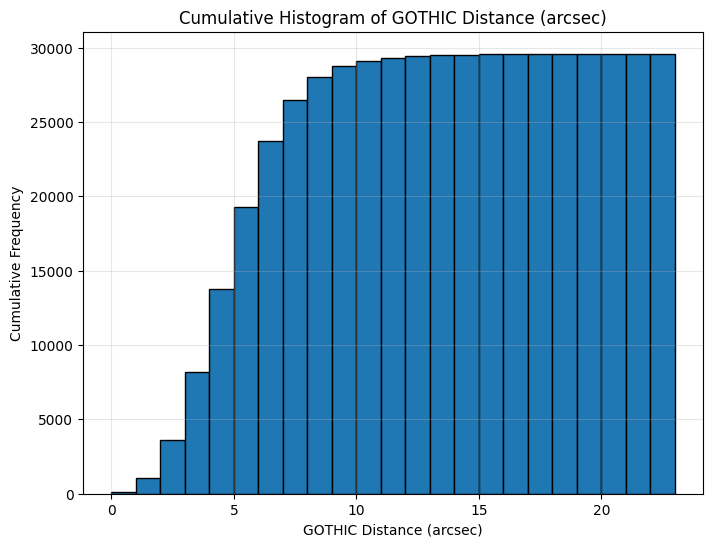

In [4]:
plt.figure(figsize=(8,6))

plt.hist(
    df['gothic_dist_arcsec'].dropna(),
    bins=bins,
    cumulative=True,
    edgecolor='black'
)

plt.xlabel('GOTHIC Distance (arcsec)')
plt.ylabel('Cumulative Frequency')
plt.title('Cumulative Histogram of GOTHIC Distance (arcsec)')
plt.grid(alpha=0.3)

plt.show()

In [5]:
arcsec_table.to_csv(
    "gothic_arcsec_frequency_table.csv",
    index=False
)

print("Saved gothic_arcsec_frequency_table.csv")

Saved gothic_arcsec_frequency_table.csv


In [11]:
# Keep only non-negative values
kpc_data = df.loc[df['gothic_delta_s_kpc'] >= 0, 'gothic_delta_s_kpc'].dropna()

bin_width = 1
bins = np.arange(0, kpc_data.max() + bin_width, bin_width)

# Histogram statistics
# Frequencies
freq, edges = np.histogram(kpc_data, bins=bins)
cumfreq= np.cumsum(freq)

# Table
kpc_table = pd.DataFrame({
    'Bin Start (kpc)': edges[:-1],
    'Bin End (kpc)': edges[1:],
    'Frequency': freq,
    'Cumulative Frequency': cumfreq
})

display(kpc_table)

,Bin Start (kpc),Bin End (kpc),Frequency,Cumulative Frequency
0,0.0,1.0,284,284
1,1.0,2.0,303,587
2,2.0,3.0,688,1275
3,3.0,4.0,1263,2538
4,4.0,5.0,1504,4042
...,...,...,...,...
87,87.0,88.0,0,29515
88,88.0,89.0,0,29515
89,89.0,90.0,0,29515
90,90.0,91.0,0,29515


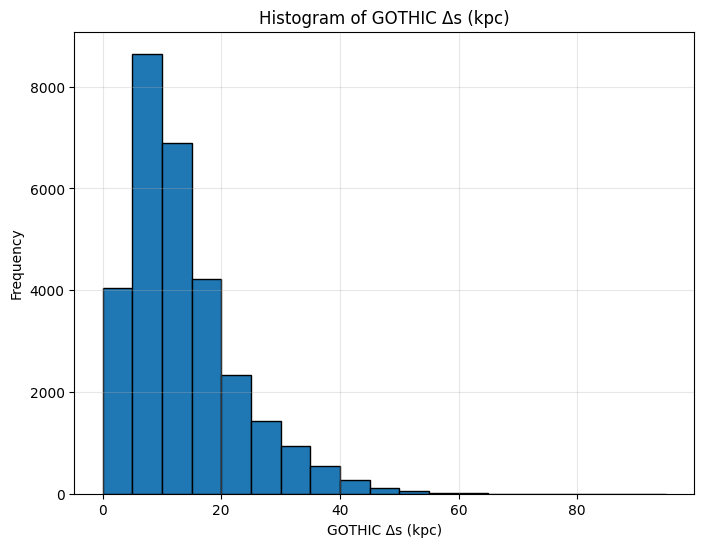

In [7]:
plt.figure(figsize=(8,6))

plt.hist(
    kpc_data,
    bins=bins,
    edgecolor='black'
)

plt.xlabel('GOTHIC Δs (kpc)')
plt.ylabel('Frequency')
plt.title('Histogram of GOTHIC Δs (kpc)')
plt.grid(alpha=0.3)

plt.show()

In [8]:
plt.figure(figsize=(8,6))

plt.hist(
    df['gothic_delta_s_kpc'].dropna(),
    bins=bins_kpc,
    cumulative=True,
    edgecolor='black'
)

plt.xlabel('GOTHIC Δs (kpc)')
plt.ylabel('Cumulative Frequency')
plt.title('Cumulative Histogram of GOTHIC Δs (kpc)')
plt.grid(alpha=0.3)

plt.show()

NameError: name 'bins_kpc' is not defined

<Figure size 800x600 with 0 Axes>

In [ ]:
kpc_table.to_csv(
    "gothic_kpc_frequency_table.csv",
    index=False
)

print("Saved gothic_kpc_frequency_table.csv")

Saved gothic_kpc_frequency_table.csv




0.0-5.0      4042
5.0-0.0      8649
10.0-15.0    6888
15.0-20.0    4215
20.0-25.0    2336
25.0-30.0    1430
30.0-35.0    942
35.0-40.0    536
40.0-45.0    276
45.0-50.0    110
50.0-55.0    51
55.0-60.0    20
60.0-65.0    11
65.0-70.0    4
70.0-75.0    2
75.0-80.0    1
80.0-85.0    2
85.0-90.0    0
90.0-95.0    1